In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.home() / "Documents" / "airline-delay-reliability-analysis"

monthly_dir = project_root / "data" / "processed" / "monthly"
figures_dir = project_root / "figures"

parquet_files = sorted(
    monthly_dir.glob("flights_2025_*.parquet")
)

model_columns = [
    "FlightDate",
    "Month",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Origin",
    "Dest",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance",
    "ArrDel15",
    "Cancelled",
    "Diverted"
]

monthly_dfs = []

for file in parquet_files:
    month_df = pd.read_parquet(
        file,
        columns=model_columns,
        engine="pyarrow"
    )
    monthly_dfs.append(month_df)

model_df = pd.concat(
    monthly_dfs,
    ignore_index=True
)

memory_mb = (
    model_df.memory_usage(deep=True).sum()
    / 1024**2
)

print(f"Rows before target filtering: {len(model_df):,}")
print(f"Columns: {model_df.shape[1]}")
print(f"Memory usage: {memory_mb:.2f} MB")
print()
print("ArrDel15 distribution:")
print(model_df["ArrDel15"].value_counts(dropna=False))

Rows before target filtering: 4,518,993
Columns: 13
Memory usage: 482.68 MB

ArrDel15 distribution:
ArrDel15
0.0    3456473
1.0     973775
NaN      88745
Name: count, dtype: int64


In [2]:
model_df["FlightDate"] = pd.to_datetime(
    model_df["FlightDate"]
)

modeling_df = model_df[
    (model_df["Cancelled"] == 0)
    & (model_df["Diverted"] == 0)
    & (model_df["ArrDel15"].notna())
].copy()

modeling_df["ArrDel15"] = (
    modeling_df["ArrDel15"].astype(int)
)

train_df = modeling_df[
    modeling_df["Month"] <= 9
].copy()

validation_df = modeling_df[
    modeling_df["Month"].isin([10, 11])
].copy()

test_df = modeling_df[
    modeling_df["Month"] == 12
].copy()


def print_split_summary(name, df):
    delay_rate = df["ArrDel15"].mean() * 100
    
    print(
        f"{name}: "
        f"{len(df):,} rows | "
        f"Delay rate: {delay_rate:.2f}% | "
        f"{df['FlightDate'].min().date()} "
        f"to {df['FlightDate'].max().date()}"
    )


print(f"Modeling sample: {len(modeling_df):,} rows")
print()

print_split_summary("Train", train_df)
print_split_summary("Validation", validation_df)
print_split_summary("Test", test_df)

print()
print(
    f"Total split rows: "
    f"{len(train_df) + len(validation_df) + len(test_df):,}"
)

Modeling sample: 4,430,248 rows

Train: 3,306,310 rows | Delay rate: 22.04% | 2025-01-01 to 2025-09-30
Validation: 752,724 rows | Delay rate: 19.51% | 2025-10-01 to 2025-11-30
Test: 371,214 rows | Delay rate: 26.42% | 2025-12-01 to 2025-12-31

Total split rows: 4,430,248


In [3]:
def add_model_features(df):
    df = df.copy()

    dep_time = df["CRSDepTime"].fillna(0).astype(int)
    arr_time = df["CRSArrTime"].fillna(0).astype(int)

    df["scheduled_dep_hour"] = dep_time // 100
    df["scheduled_arr_hour"] = arr_time // 100

    df["scheduled_dep_hour"] = (
        df["scheduled_dep_hour"]
        .replace(24, 0)
    )

    df["scheduled_arr_hour"] = (
        df["scheduled_arr_hour"]
        .replace(24, 0)
    )

    df["departure_time_band"] = pd.cut(
        df["scheduled_dep_hour"],
        bins=[-1, 7, 10, 13, 16, 19, 23],
        labels=[
            "Early Morning",
            "Morning",
            "Midday",
            "Afternoon",
            "Evening",
            "Night"
        ]
    )

    return df


train_df = add_model_features(train_df)
validation_df = add_model_features(validation_df)
test_df = add_model_features(test_df)


categorical_features = [
    "Marketing_Airline_Network",
    "Origin",
    "Dest",
    "Month",
    "DayOfWeek",
    "departure_time_band"
]

numerical_features = [
    "scheduled_dep_hour",
    "scheduled_arr_hour",
    "CRSElapsedTime",
    "Distance"
]

target = "ArrDel15"

print("Categorical features:")
for col in categorical_features:
    print(
        f"{col}: "
        f"{train_df[col].nunique()} unique values"
    )

print("\nNumerical features:")
for col in numerical_features:
    print(
        f"{col}: "
        f"missing = {train_df[col].isna().sum():,}"
    )

print("\nTarget:")
print(train_df[target].value_counts())

Categorical features:
Marketing_Airline_Network: 3 unique values
Origin: 310 unique values
Dest: 310 unique values
Month: 9 unique values
DayOfWeek: 7 unique values
departure_time_band: 6 unique values

Numerical features:
scheduled_dep_hour: missing = 0
scheduled_arr_hour: missing = 0
CRSElapsedTime: missing = 0
Distance: missing = 0

Target:
ArrDel15
0    2577512
1     728798
Name: count, dtype: int64


In [4]:
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print(f"scikit-learn version: {sklearn.__version__}")

X_train = train_df[
    categorical_features + numerical_features
].copy()

y_train = train_df[target].copy()

X_validation = validation_df[
    categorical_features + numerical_features
].copy()

y_validation = validation_df[target].copy()

X_test = test_df[
    categorical_features + numerical_features
].copy()

y_test = test_df[target].copy()


preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)


logistic_model = LogisticRegression(
    solver="saga",
    max_iter=150,
    C=1.0,
    random_state=42
)


logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model)
    ]
)


print()
print(f"X_train shape: {X_train.shape}")
print(f"X_validation shape: {X_validation.shape}")
print(f"X_test shape: {X_test.shape}")

print()
print(logistic_pipeline)

scikit-learn version: 1.9.0

X_train shape: (3306310, 10)
X_validation shape: (752724, 10)
X_test shape: (371214, 10)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Marketing_Airline_Network',
                                                   'Origin', 'Dest', 'Month',
                                                   'DayOfWeek',
                                                   'departure_time_band']),
                                                 ('numerical', StandardScaler(),
                                                  ['scheduled_dep_hour',
                                                   'scheduled_arr_hour',
                                                   'CRSElapsedTime',
                                                   'Distance'])])),
                ('model',
     

In [5]:
import time

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

start_time = time.time()

logistic_pipeline.fit(
    X_train,
    y_train
)

training_minutes = (time.time() - start_time) / 60

validation_prob = logistic_pipeline.predict_proba(
    X_validation
)[:, 1]

validation_pred_05 = (
    validation_prob >= 0.50
).astype(int)

roc_auc = roc_auc_score(
    y_validation,
    validation_prob
)

pr_auc = average_precision_score(
    y_validation,
    validation_prob
)

precision = precision_score(
    y_validation,
    validation_pred_05,
    zero_division=0
)

recall = recall_score(
    y_validation,
    validation_pred_05,
    zero_division=0
)

f1 = f1_score(
    y_validation,
    validation_pred_05,
    zero_division=0
)

cm = confusion_matrix(
    y_validation,
    validation_pred_05
)

print(f"Training time: {training_minutes:.2f} minutes")

print("\nValidation metrics at threshold = 0.50")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

Training time: 3.77 minutes

Validation metrics at threshold = 0.50
ROC-AUC:   0.6369
PR-AUC:    0.2922
Precision: 0.4313
Recall:    0.0164
F1 Score:  0.0317

Confusion Matrix:
[[602647   3186]
 [144475   2416]]


In [6]:
thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

threshold_results = []

for threshold in thresholds:
    pred = (
        validation_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_validation,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_validation,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        pred,
        zero_division=0
    )

    predicted_positive_rate = (
        pred.mean() * 100
    )

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predicted_high_risk_pct": predicted_positive_rate
    })


threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
] = threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
].round(4)

threshold_df

,threshold,precision,recall,f1,predicted_high_risk_pct
0,0.10,0.1984,0.9897,0.3305,97.3621
1,0.15,0.2124,0.9222,0.3453,84.7187
2,0.20,0.2334,0.7991,0.3613,66.8043
3,0.25,0.2575,0.6565,0.3699,49.7591
4,0.30,0.2821,0.5027,0.3614,34.7745
5,0.35,0.3160,0.3313,0.3235,20.4553
6,0.40,0.3576,0.1719,0.2322,9.3805
7,0.45,0.4002,0.0660,0.1134,3.2199
8,0.50,0.4313,0.0164,0.0317,0.7442


In [7]:
business_threshold = 0.30

validation_pred_business = (
    validation_prob >= business_threshold
).astype(int)

business_cm = confusion_matrix(
    y_validation,
    validation_pred_business
)

business_precision = precision_score(
    y_validation,
    validation_pred_business,
    zero_division=0
)

business_recall = recall_score(
    y_validation,
    validation_pred_business,
    zero_division=0
)

business_f1 = f1_score(
    y_validation,
    validation_pred_business,
    zero_division=0
)

high_risk_rate = (
    validation_pred_business.mean() * 100
)

baseline_delay_rate = (
    y_validation.mean() * 100
)

risk_lift = (
    business_precision
    / y_validation.mean()
)

print(f"Business threshold: {business_threshold:.2f}")
print(f"Validation baseline delay rate: {baseline_delay_rate:.2f}%")
print(f"Precision: {business_precision:.4f}")
print(f"Recall: {business_recall:.4f}")
print(f"F1 Score: {business_f1:.4f}")
print(f"Flights flagged high risk: {high_risk_rate:.2f}%")
print(f"Risk lift vs baseline: {risk_lift:.2f}x")

print("\nConfusion Matrix:")
print(business_cm)


Business threshold: 0.30
Validation baseline delay rate: 19.51%
Precision: 0.2821
Recall: 0.5027
F1 Score: 0.3614
Flights flagged high risk: 34.77%
Risk lift vs baseline: 1.45x

Confusion Matrix:
[[417920 187913]
 [ 73048  73843]]


In [8]:
rf_sample_fraction = 800_000 / len(train_df)

rf_train_df = (
    train_df
    .groupby(
        target,
        group_keys=False
    )
    .sample(
        frac=rf_sample_fraction,
        random_state=42
    )
    .sample(
        frac=1,
        random_state=42
    )
    .reset_index(drop=True)
)

print(f"Random Forest training rows: {len(rf_train_df):,}")
print()

print("Target distribution:")
print(
    rf_train_df[target]
    .value_counts()
    .sort_index()
)

print()

print(
    "Delay rate: "
    f"{rf_train_df[target].mean() * 100:.2f}%"
)

Random Forest training rows: 800,000

Target distribution:
ArrDel15
0    623659
1    176341
Name: count, dtype: int64

Delay rate: 22.04%


In [9]:
from sklearn.ensemble import RandomForestClassifier

X_rf_train = rf_train_df[
    categorical_features + numerical_features
].copy()

y_rf_train = rf_train_df[target].copy()


rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)


rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=50,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.60,
    n_jobs=-1,
    random_state=42
)


rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", rf_model)
    ]
)


print(f"RF training shape: {X_rf_train.shape}")
print()
print(rf_model)

RF training shape: (800000, 10)

RandomForestClassifier(max_depth=18, max_samples=0.6, min_samples_leaf=50,
                       n_estimators=150, n_jobs=-1, random_state=42)


In [10]:
start_time = time.time()

rf_pipeline.fit(
    X_rf_train,
    y_rf_train
)

rf_training_minutes = (
    time.time() - start_time
) / 60

rf_validation_prob = rf_pipeline.predict_proba(
    X_validation
)[:, 1]

rf_validation_pred_05 = (
    rf_validation_prob >= 0.50
).astype(int)

rf_roc_auc = roc_auc_score(
    y_validation,
    rf_validation_prob
)

rf_pr_auc = average_precision_score(
    y_validation,
    rf_validation_prob
)

rf_precision = precision_score(
    y_validation,
    rf_validation_pred_05,
    zero_division=0
)

rf_recall = recall_score(
    y_validation,
    rf_validation_pred_05,
    zero_division=0
)

rf_f1 = f1_score(
    y_validation,
    rf_validation_pred_05,
    zero_division=0
)

rf_cm = confusion_matrix(
    y_validation,
    rf_validation_pred_05
)

print(f"RF training time: {rf_training_minutes:.2f} minutes")

print("\nRandom Forest Validation Metrics at threshold = 0.50")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")
print(f"PR-AUC:    {rf_pr_auc:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")

print("\nConfusion Matrix:")
print(rf_cm)

RF training time: 0.63 minutes

Random Forest Validation Metrics at threshold = 0.50
ROC-AUC:   0.6306
PR-AUC:    0.2871
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000

Confusion Matrix:
[[605833      0]
 [146891      0]]


In [11]:
print("Random Forest validation probability distribution:")

print(
    pd.Series(rf_validation_prob)
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print()
print(
    f"Maximum predicted probability: "
    f"{rf_validation_prob.max():.4f}"
)

Random Forest validation probability distribution:
count    752724.000000
mean          0.219417
std           0.064315
min           0.093237
50%           0.209701
75%           0.276790
90%           0.307558
95%           0.321839
99%           0.342684
max           0.378204
dtype: float64

Maximum predicted probability: 0.3782


In [12]:
rf_thresholds = [
    0.15,
    0.18,
    0.20,
    0.22,
    0.24,
    0.26,
    0.28,
    0.30,
    0.32,
    0.34
]

rf_threshold_results = []

for threshold in rf_thresholds:
    pred = (
        rf_validation_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_validation,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_validation,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        pred,
        zero_division=0
    )

    predicted_high_risk_pct = (
        pred.mean() * 100
    )

    rf_threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predicted_high_risk_pct": predicted_high_risk_pct
    })

rf_threshold_df = pd.DataFrame(
    rf_threshold_results
)

rf_threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
] = rf_threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
].round(4)

rf_threshold_df

,threshold,precision,recall,f1,predicted_high_risk_pct
0,0.15,0.2148,0.9140,0.3479,83.0242
1,0.18,0.2334,0.7807,0.3593,65.2778
2,0.20,0.2474,0.6839,0.3633,53.9437
3,0.22,0.2568,0.6157,0.3624,46.7891
4,0.24,0.2673,0.5567,0.3612,40.6405
5,0.26,0.2807,0.4780,0.3537,33.2377
6,0.28,0.3019,0.3604,0.3286,23.2915
7,0.30,0.3248,0.2245,0.2655,13.4901
8,0.32,0.3711,0.1062,0.1651,5.5844
9,0.34,0.4276,0.0281,0.0527,1.2820


In [13]:
try:
    import xgboost as xgb
    print(f"XGBoost version: {xgb.__version__}")
    print("XGBoost is ready.")
except ImportError:
    print("XGBoost is not installed.")
    

XGBoost is not installed.


In [14]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 3.9/48.9 MB 21.1 MB/s eta 0:00:03
   ----- ---------------------------------- 6.3/48.9 MB 15.1 MB/s eta 0:00:03
   ------ --------------------------------- 8.4/48.9 MB 13.5 MB/s eta 0:00:03
   -------- ------------------------------- 10.7/48.9 MB 12.7 MB/s eta 0:00:04
   ---------- ----------------------------- 12.8/48.9 MB 12.2 MB/s eta 0:00:03
   ------------ --------------------------- 15.2/48.9 MB 11.9 MB/s eta 0:00:03
   -------------- ------------------------- 17.3/48.9 MB 11.7 MB/s eta 0:00:03
   --------------- ------------------------ 19.4/48.9 MB 11.5 MB/s eta 0:00:03
   ----------------- ---------------------- 21.5/48.9 MB 11.3 MB/s eta 0:00:03
   ------------------- -------------------- 23.9/48.9 MB 11.3 MB/s eta 0:00:03
   -------------------- ------------------- 25.4/48.9 MB 11.1 MB/s eta 0:00:03
   ---------------------- ----------------- 27.8/48.9 MB 10.9 MB


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import xgboost as xgb

print(f"XGBoost version: {xgb.__version__}")
print("XGBoost is ready.")

XGBoost version: 3.4.1
XGBoost is ready.


In [16]:
import xgboost as xgb

print(f"XGBoost version: {xgb.__version__}")
print("XGBoost is ready.")

XGBoost version: 3.4.1
XGBoost is ready.


In [17]:
from xgboost import XGBClassifier

xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)


xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    min_child_weight=20,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)


xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", xgb_preprocessor),
        ("model", xgb_model)
    ]
)


print(f"XGBoost training shape: {X_rf_train.shape}")
print()
print(xgb_model)

XGBoost training shape: (800000, 10)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=20, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [18]:
start_time = time.time()

xgb_pipeline.fit(
    X_rf_train,
    y_rf_train
)

xgb_training_minutes = (
    time.time() - start_time
) / 60

xgb_validation_prob = xgb_pipeline.predict_proba(
    X_validation
)[:, 1]

xgb_validation_pred_05 = (
    xgb_validation_prob >= 0.50
).astype(int)

xgb_roc_auc = roc_auc_score(
    y_validation,
    xgb_validation_prob
)

xgb_pr_auc = average_precision_score(
    y_validation,
    xgb_validation_prob
)

xgb_precision = precision_score(
    y_validation,
    xgb_validation_pred_05,
    zero_division=0
)

xgb_recall = recall_score(
    y_validation,
    xgb_validation_pred_05,
    zero_division=0
)

xgb_f1 = f1_score(
    y_validation,
    xgb_validation_pred_05,
    zero_division=0
)

xgb_cm = confusion_matrix(
    y_validation,
    xgb_validation_pred_05
)

print(f"XGBoost training time: {xgb_training_minutes:.2f} minutes")

print("\nXGBoost Validation Metrics at threshold = 0.50")
print(f"ROC-AUC:   {xgb_roc_auc:.4f}")
print(f"PR-AUC:    {xgb_pr_auc:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1 Score:  {xgb_f1:.4f}")

print("\nConfusion Matrix:")
print(xgb_cm)

XGBoost training time: 0.29 minutes

XGBoost Validation Metrics at threshold = 0.50
ROC-AUC:   0.6434
PR-AUC:    0.2982
Precision: 0.5953
Recall:    0.0009
F1 Score:  0.0017

Confusion Matrix:
[[605746     87]
 [146763    128]]


In [19]:
xgb_thresholds = [
    0.15,
    0.18,
    0.20,
    0.22,
    0.24,
    0.26,
    0.28,
    0.30,
    0.32,
    0.34,
    0.36,
    0.38,
    0.40
]

xgb_threshold_results = []

for threshold in xgb_thresholds:
    pred = (
        xgb_validation_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_validation,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_validation,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        pred,
        zero_division=0
    )

    predicted_high_risk_pct = (
        pred.mean() * 100
    )

    xgb_threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predicted_high_risk_pct": predicted_high_risk_pct
    })


xgb_threshold_df = pd.DataFrame(
    xgb_threshold_results
)

xgb_threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
] = xgb_threshold_df[
    [
        "precision",
        "recall",
        "f1",
        "predicted_high_risk_pct"
    ]
].round(4)

xgb_threshold_df

,threshold,precision,recall,f1,predicted_high_risk_pct
0,0.15,0.2289,0.8502,0.3607,72.4745
1,0.18,0.2456,0.7435,0.3693,59.0612
2,0.20,0.2595,0.6592,0.3723,49.5801
3,0.22,0.2738,0.5757,0.3711,41.0278
4,0.24,0.2880,0.4948,0.3641,33.5311
5,0.26,0.3039,0.4089,0.3486,26.2565
6,0.28,0.3214,0.3205,0.3210,19.4580
7,0.30,0.3411,0.2449,0.2851,14.0123
8,0.32,0.3618,0.1779,0.2385,9.5937
9,0.34,0.3819,0.1222,0.1852,6.2457


In [20]:
final_threshold = 0.24

xgb_test_prob = xgb_pipeline.predict_proba(
    X_test
)[:, 1]

xgb_test_pred = (
    xgb_test_prob >= final_threshold
).astype(int)

test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

test_pr_auc = average_precision_score(
    y_test,
    xgb_test_prob
)

test_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

test_cm = confusion_matrix(
    y_test,
    xgb_test_pred
)

test_high_risk_pct = (
    xgb_test_pred.mean() * 100
)

test_baseline_delay_rate = (
    y_test.mean() * 100
)

test_risk_lift = (
    test_precision / y_test.mean()
)

print("FINAL OUT-OF-TIME TEST RESULTS")
print("--------------------------------")
print(f"Test period: December 2025")
print(f"Business threshold: {final_threshold:.2f}")
print(f"Baseline delay rate: {test_baseline_delay_rate:.2f}%")
print()

print(f"ROC-AUC:   {test_roc_auc:.4f}")
print(f"PR-AUC:    {test_pr_auc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")

print()
print(f"Flights flagged high risk: {test_high_risk_pct:.2f}%")
print(f"Risk lift vs baseline: {test_risk_lift:.2f}x")

print("\nConfusion Matrix:")
print(test_cm)

FINAL OUT-OF-TIME TEST RESULTS
--------------------------------
Test period: December 2025
Business threshold: 0.24
Baseline delay rate: 26.42%

ROC-AUC:   0.6084
PR-AUC:    0.3459
Precision: 0.3480
Recall:    0.4271
F1 Score:  0.3835

Flights flagged high risk: 32.43%
Risk lift vs baseline: 1.32x

Confusion Matrix:
[[194631  78497]
 [ 56196  41890]]


In [21]:
feature_names = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": (
        xgb_pipeline
        .named_steps["model"]
        .feature_importances_
    )
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 individual features:")
display(feature_importance.head(20))

def get_feature_group(feature_name):
    if "Marketing_Airline_Network" in feature_name:
        return "Airline"
    elif "Origin_" in feature_name:
        return "Origin Airport"
    elif "Dest_" in feature_name:
        return "Destination Airport"
    elif "Month_" in feature_name:
        return "Month"
    elif "DayOfWeek_" in feature_name:
        return "Day of Week"
    elif "departure_time_band_" in feature_name:
        return "Departure Time Band"
    elif "scheduled_dep_hour" in feature_name:
        return "Scheduled Departure Hour"
    elif "scheduled_arr_hour" in feature_name:
        return "Scheduled Arrival Hour"
    elif "CRSElapsedTime" in feature_name:
        return "Scheduled Flight Duration"
    elif "Distance" in feature_name:
        return "Distance"
    else:
        return "Other"


feature_importance["feature_group"] = (
    feature_importance["feature"]
    .apply(get_feature_group)
)

group_importance = (
    feature_importance
    .groupby("feature_group", as_index=False)["importance"]
    .sum()
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAggregated feature importance:")
display(group_importance)

Top 20 individual features:


,feature,importance
0,categorical__Month_6,0.037195
1,categorical__Month_7,0.034774
2,numerical__scheduled_arr_hour,0.019720
3,categorical__departure_time_band_Early Morning,0.017789
4,categorical__Origin_SLC,0.015791
5,categorical__Month_9,0.014936
6,categorical__Origin_LAX,0.013834
7,categorical__Origin_SFO,0.010893
8,categorical__Dest_EWR,0.010580
9,categorical__Dest_SLC,0.010502



Aggregated feature importance:


,feature_group,importance
0,Origin Airport,0.403052
1,Destination Airport,0.355211
2,Month,0.124577
3,Departure Time Band,0.036110
4,Day of Week,0.033963
5,Scheduled Arrival Hour,0.019720
6,Airline,0.014812
7,Scheduled Departure Hour,0.008834
8,Distance,0.002279
9,Scheduled Flight Duration,0.001441


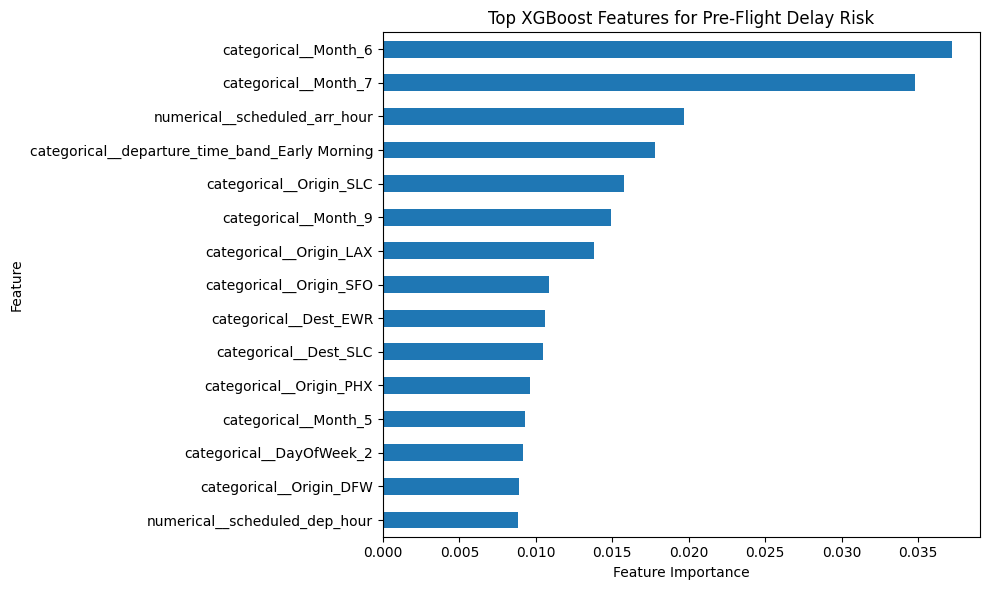

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\xgboost_feature_importance.png


In [22]:
top_features = (
    feature_importance
    .head(15)
    .sort_values(
        "importance",
        ascending=True
    )
)

ax = top_features.plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

ax.set_title("Top XGBoost Features for Pre-Flight Delay Risk")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Feature")

plt.tight_layout()

output_path = (
    figures_dir
    / "xgboost_feature_importance.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

                     ROC-AUC  PR-AUC
Model                               
Logistic Regression   0.6369  0.2922
Random Forest         0.6306  0.2871
XGBoost               0.6434  0.2982


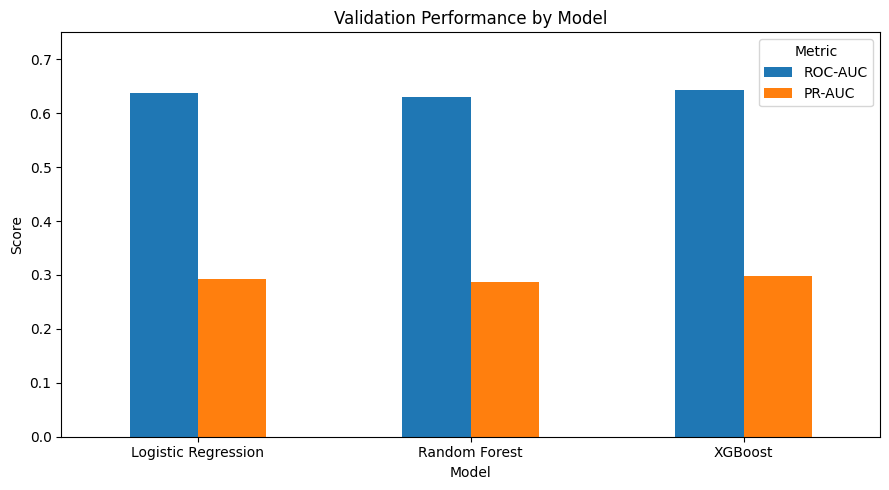

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\model_validation_comparison.png


In [23]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ],
    "PR-AUC": [
        pr_auc,
        rf_pr_auc,
        xgb_pr_auc
    ]
})

model_comparison = model_comparison.set_index("Model")

print(model_comparison.round(4))

ax = model_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Validation Performance by Model")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 0.75)
ax.legend(title="Metric")

plt.xticks(rotation=0)
plt.tight_layout()

output_path = figures_dir / "model_validation_comparison.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

In [24]:
day5_findings = """# Day 5 - Pre-Flight Delay Prediction: Key Findings

## 1. Modeling Objective

The prediction target is whether a normally operated flight arrives at least 15 minutes late:

ArrDel15 = 1

Only information available before scheduled departure was used.

Post-departure variables such as departure delay, arrival delay, taxi time, and delay-cause variables were excluded to prevent data leakage.

## 2. Temporal Validation Design

The dataset was split chronologically rather than randomly.

- Training: January-September 2025
- Validation: October-November 2025
- Out-of-time Test: December 2025

Modeling sample:
4,430,248 completed, non-diverted flights.

Delay rates:

- Train: 22.04%
- Validation: 19.51%
- Test: 26.42%

December therefore represents a more difficult high-delay operating environment.

## 3. Logistic Regression Baseline

Validation performance:

- ROC-AUC: 0.6369
- PR-AUC: 0.2922

The default 0.50 threshold produced very low recall.

A business threshold of 0.30 was selected for comparison:

- Precision: 28.21%
- Recall: 50.27%
- F1: 0.3614
- Flights flagged high risk: 34.77%
- Risk lift vs validation baseline: 1.45x

## 4. Random Forest

Validation performance:

- ROC-AUC: 0.6306
- PR-AUC: 0.2871

At a threshold of 0.26:

- Precision: 28.07%
- Recall: 47.80%
- F1: 0.3537
- Flights flagged high risk: 33.24%

Random Forest did not outperform Logistic Regression.

## 5. XGBoost

Validation performance:

- ROC-AUC: 0.6434
- PR-AUC: 0.2982

XGBoost provided a modest but consistent improvement over Logistic Regression and Random Forest.

A business threshold of 0.24 was selected.

Validation performance at threshold 0.24:

- Precision: 28.80%
- Recall: 49.48%
- F1: 0.3641
- Flights flagged high risk: 33.53%

The highest validation F1 was 0.3723 at threshold 0.20, but the 0.24 threshold was selected to maintain a more manageable operational alert volume.

## 6. Final Out-of-Time Test

The final model and threshold were evaluated once on December 2025.

Results:

- Baseline delay rate: 26.42%
- ROC-AUC: 0.6084
- PR-AUC: 0.3459
- Precision: 34.80%
- Recall: 42.71%
- F1: 0.3835
- Flights flagged high risk: 32.43%
- Risk lift vs baseline: 1.32x

The decline in ROC-AUC from validation to December suggests temporal and seasonal distribution shift during a more difficult operating period.

The test results were not used to retune the model or decision threshold.

## 7. Model Interpretation

Important individual XGBoost features included:

- June
- July
- Scheduled arrival hour
- Early-morning departure indicator
- Origin SLC
- September
- Origin LAX
- Origin SFO
- Destination EWR
- Origin DFW

Aggregated feature importance indicates that airport location, seasonality, and scheduled timing are the most informative pre-flight feature groups.

Feature importance should be interpreted as predictive importance rather than causal importance.

## 8. Business Interpretation

The final model should be viewed as a pre-flight risk prioritization tool rather than a deterministic delay predictor.

It can help operations teams identify a smaller group of flights with elevated delay risk before departure.

At the selected threshold, approximately one-third of flights are flagged for additional attention.

Potential operational uses include:

- proactive aircraft and crew monitoring
- targeted turnaround support
- schedule recovery preparation
- high-risk flight watchlists
- prioritization of limited operational resources

The prediction model complements the root-cause and propagation analyses rather than replacing them.
"""

docs_dir = project_root / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

findings_path = docs_dir / "day5_model_findings.md"

findings_path.write_text(
    day5_findings,
    encoding="utf-8"
)

print(f"Saved to: {findings_path}")

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\docs\day5_model_findings.md
